# STATE OPUS-R2 — GO annotation count and perturbation strength

All analysis code is inline. Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, statsmodels 0.14.2, matplotlib 3.9.4, RDKit 2026.3.3, IPython and ipykernel. Model evaluation uses released scores; no inference is required. `STATE_PUBLIC_INPUTS` and `STATE_RELEASE_INPUTS` can select verified raw caches.

## 1. Data source and acquisition

Download the pinned official STATE per-condition score files. The checksum-pinned companion bundle supplies condition identities, drug annotations and dated ontology membership snapshots.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,zipfile,shutil,ast,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,pearsonr,rankdata,mannwhitneyu
import statsmodels.api as sm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
START=time.time()
CACHE=Path(os.environ.get('STATE_PUBLIC_INPUTS','state_public_inputs')).resolve();CACHE.mkdir(parents=True,exist_ok=True)
RELEASES=Path(os.environ.get('STATE_RELEASE_INPUTS','state_releases')).resolve();RELEASES.mkdir(parents=True,exist_ok=True)
WORK=Path('test-05_outputs').resolve();(WORK/'data').mkdir(parents=True,exist_ok=True);(WORK/'spectra_run/artifacts').mkdir(parents=True,exist_ok=True)
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def fetch(url,p,size,digest):
    if p.exists() and p.stat().st_size==size and sha(p)==digest:return p
    p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix(p.suffix+'.part')
    with urllib.request.urlopen(urllib.request.Request(url,headers={'User-Agent':'STATE-notebook/1.0'}),timeout=180) as source,tmp.open('wb') as target:
        shutil.copyfileobj(source,target,8388608)
    if tmp.stat().st_size!=size or sha(tmp)!=digest:raise ValueError('Source identity mismatch: '+str(p))
    tmp.replace(p);return p
archive=fetch('https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/state-inputs.zip',CACHE/'state-inputs.zip',440390168,'fb45e9305dcf32bfa9d68ff910f7539707b3e4ff58c695db2e8c5ee8a9e8a9fc')
P=CACHE/'public_bundle/assets/state-opus-r2'
with zipfile.ZipFile(archive) as z:
    inventory=json.loads(z.read('STATE_INPUTS.json'))
    required=[k for k in inventory if k.startswith('state-opus-r2/') and (k.endswith('data/predictions.csv') or ('spectra_run/artifacts/' in k and k.endswith('.json')))]
    for k in required:
        target=CACHE/'public_bundle/assets'/k;x=inventory[k]
        if target.exists() and target.stat().st_size==x['bytes'] and sha(target)==x['sha256']:continue
        target.parent.mkdir(parents=True,exist_ok=True)
        with z.open('assets/'+k) as source,target.open('wb') as dest:shutil.copyfileobj(source,dest)
        if sha(target)!=x['sha256']:raise ValueError(k)
print('Verified input annotation files:',len(required))

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


Verified input annotation files: 8


In [2]:
SOURCES = [{'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 276570,
  'sha256': 'ca5377b00f6700bee2b4b17eeaf4e703fc2d3797ac8271c2f282088fcbb289e8',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269473,
  'sha256': '489cbe64636b7765fe7f24fe5536da9fb1ee86226effd9eeb422634d5731396b',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 284828,
  'sha256': '49e3ce723ec7ca6bfc044d438902129ffb9ec2682d33a73e16693735c4746ad4',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 275993,
  'sha256': 'f391f46e60061332b2a555567443aeb3190239c4bdac146bcb3340d503aeebe9',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 272057,
  'sha256': '2654fe5b526d577807a63b30a9c85a70d829979afe452325650071a3f22a03ae',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 281263,
  'sha256': '9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269030,
  'sha256': '646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 287583,
  'sha256': '9106d01893815fbf77d85f4e2351da8a607adedc74edb62cc452c110812b09a2',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 277100,
  'sha256': '80c38255fdce0444457f909d7ef9c2186a82c5476550bfe82604bd48896aae72',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 273025,
  'sha256': '5a40d67c26a428487d3b0f602b5b7a69006b5c4595eaaf0ffb5f44eaf5160239',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 360951,
  'sha256': '42dd8ef412843c9e0782c72d669ef352d40af63fbe7f1d11ab26b9d0f188a5e3',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 423657,
  'sha256': 'fff2d8598e61229052483d2215809b267a9be5b28187147ea8eaa078a115280d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 368088,
  'sha256': 'c518efe5a6492b62dd3aea985e6f50ca5a8b2e9df742134041e313d2e6605ba6',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 406063,
  'sha256': '397533d40a2efba9d75a54fca855fc39db1562ff50c765408e9afdea61826803',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 354986,
  'sha256': '1e4cd7df90212c61f7f171fcd5da69449e5e3edde4462201b8dedd99d07aa2c4',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 403167,
  'sha256': '7352c785869bf83402fb5dc79ebdbb2d911d77153c3530db4b9f143a5bec2626',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 365675,
  'sha256': 'bcba9ae671c391e78b11efda0bb0d3d48f8052541ae7599d522b293e96e3594c',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 411935,
  'sha256': '36b6afce7889485a2afa99a13449b59dbd06d14d564e985a37629f93101ffd34',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23267,
  'sha256': '09553a37706d948fddf8cf5bacf5b88880cf3cfb90a2b866f08524b49e909401',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22921,
  'sha256': 'e9d288b06289e24e7928b9a79ccce8ed74a702c9b2fdf92c5a6470aeb11cdbc1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20723,
  'sha256': '202ca8338564bcdc2a7c68007b0976800b4dbb7ca5e6d8a0799b0d428615233c',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 21260,
  'sha256': '13935da60494fb572039e10aed4f44748bf9e7e8dd0ee2acf4fe8bcfe158a852',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21542,
  'sha256': '1030abc5a7bd1cb1b9c692c35ba4ce16d0515d299dec9c7cf50eb2ede9641a65',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33745,
  'sha256': 'f6a553831669d4f5fb0a6957d7f32e815a4fa5be89a0cf13677396b6039aa157',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 32762,
  'sha256': '9a7f4a4c564d25dc2cfe06e25367ae936dc50873aa5711ad26e5d1e3f46d0916',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 27434,
  'sha256': '50b1d9d6f15cbd9d27ccb17e07605f21b94a0e461d346555d81b7d911694d5ec',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31420,
  'sha256': '84f0f00cd17c871b879ee38d92ce5183241c38e1afb20405f3b00e361c98eaa1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 31512,
  'sha256': 'df68464d3caf07c7c5129a0d911d10ba17c75020e7ac866e4afde28155ac4786',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23028,
  'sha256': '06ef8b31481e21845e29eb3408827469eb7da67c01e17c315d2e82d77ddd325a',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22494,
  'sha256': '0073fb52db8657ccb14815b58025f53f89abde3a27eb1614c650e930375d3f60',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20130,
  'sha256': '87c04e97d215f7bda9a13d602472e62db0be919dc791ab4c4d4732f5a48cf06c',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21275,
  'sha256': '3d8466310099d70f91a69725fb0e181e1fd541f57ed644daab5c41be6ae1b88d',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33911,
  'sha256': '41377aad49e688a710264d343378e5bc6ce1a698880b8bb1c4f0be9ad025c48f',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 33789,
  'sha256': 'bb35f1b85f8d9603b10fcf8706602b122bdc520548c9c53f891386dcd40026a1',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 28814,
  'sha256': '73b37fc58ca8a8734dc5cc34c6b44ec94cdbb6ccb47dadfb3c5bccedf8c99655',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31883,
  'sha256': '2cbac97ecdeee9ae7333245fc4d06860969d17d38f2fc4ebea8f99e8af5657fa',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 30873,
  'sha256': '579286dcc83ffaead762b234891442b560b6213d847956d87147389323c7df5b',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'}]

## 2. Data processing

Join released results to exact repository/path/perturbation identities. Keep the protocol, representation, context and annotation fields explicit. Each condition is retained once.

In [3]:
# Read only source identities and annotations from the bundle; model-score columns
# are loaded separately from the pinned official CSVs below.
annotation_columns=['source_repo','source_path','dataset_family','protocol','context','split_id','representation','perturbation','perturbation_name','dose','dose_unit','perturbation_norm','perturbation_loose','row_key','drug_metadata_match']
annotation_columns += [c for c in pd.read_csv(P/'data/predictions.csv',nrows=0).columns if c.startswith('drugmeta_')]
annotations=pd.read_csv(P/'data/predictions.csv',usecols=annotation_columns,low_memory=False)
assert not annotations.duplicated(['source_repo','source_path','perturbation']).any()
score_parts=[]
for x in SOURCES:
    p=fetch(x['url'],RELEASES/x['path'],x['bytes'],x['sha256'])
    s=pd.read_csv(p);s['source_repo']=x['repo'];s['source_path']=x['filename'];score_parts.append(s)
released=pd.concat(score_parts,ignore_index=True)
raw=annotations.merge(released,on=['source_repo','source_path','perturbation'],how='left',validate='one_to_one')
assert len(raw)==len(annotations) and raw.overlap_at_N.notna().all()
raw.to_csv(WORK/'data/predictions.csv',index=False)
for p in (P/'spectra_run/artifacts').glob('*.json'):
    shutil.copy2(p,WORK/'spectra_run/artifacts'/p.name)
genes=set(raw.loc[raw.dataset_family=='Replogle-Nadig','perturbation'].str.upper())
tahoe=raw[raw.dataset_family=='Tahoe-100M'].copy()
display(raw.groupby(['dataset_family','protocol','representation']).size().rename('condition_rows'))


dataset_family  protocol  representation
Parse-PBMC      fewshot   HVG                310
                          SE                 248
                zeroshot  HVG                450
                          SE                 450
Replogle-Nadig  fewshot   HVG               4058
                          SE                4058
                zeroshot  HVG               5759
                          SE                5759
Tahoe-100M      fewshot   HVG               3674
                          SE                3674
                zeroshot  HVG               5684
                          SE                5684
Name: condition_rows, dtype: int64

## 3. Axis definition and level construction

In [4]:
import json, numpy as np, pandas as pd
from scipy.stats import spearmanr
go=json.load(open(P/'spectra_run/artifacts/go_terms.json'))
df=pd.read_csv(P/'data/predictions.csv',low_memory=False)
r=df[df.dataset_family=='Replogle-Nadig'].copy()
genes=sorted(r['perturbation_name'].unique())

BP={g:set(go.get(g,{}).get('BP',[])) for g in genes}
nbp={g:len(BP[g]) for g in genes}
have=[g for g in genes if nbp[g]>0]
print('genes with BP terms:',len(have))

# Functional neighborhood density via GO-BP Jaccard.
# For each gene, mean of top-5 Jaccard to OTHER genes = functional coverage.
# Compute efficiently via inverted index -> but Jaccard needs pairwise. Do it with sets (2023^2/2 ~ 2M, ok)
import itertools
arr=have
# Precompute for speed: represent as frozensets
S={g:BP[g] for g in arr}
# To bound cost, compute for each gene its top-k jaccard by iterating (2M ops)
top5=[]; nnj=[]
den_thr=[]  # count neighbors with jaccard>=0.2
for i,g in enumerate(arr):
    sg=S[g]; lg=len(sg)
    sims=[]
    for h in arr:
        if h==g: continue
        sh=S[h]
        inter=len(sg & sh)
        if inter==0: 
            sims.append(0.0); continue
        j=inter/(lg+len(sh)-inter)
        sims.append(j)
    sims=np.array(sims); sims.sort()
    top5.append(sims[-5:].mean()); nnj.append(sims[-1]); den_thr.append((sims>=0.2).sum())
feat=pd.DataFrame({'perturbation_name':arr,'go_nbp':[nbp[g] for g in arr],
                   'go_meantop5':top5,'go_nn':nnj,'go_ndense':den_thr})


feat.to_csv(WORK/'spectra_run/artifacts/replogle_go_features.csv',index=False)

genes with BP terms: 1911


GO-BP density is the mean of the five largest Jaccard similarities to other annotated genes; self-membership is excluded. Quartiles are assigned across genes, independently of context and model score.

## 4. Model results and released scores

The primary metric is released `overlap_at_N`; higher is better. Fixed-N overlaps, DE counts, representation changes and protocol changes remain separate controls. Drug-level analyses average all eligible condition rows within drug.

In [5]:
display(raw.groupby(['dataset_family','protocol','representation']).agg(n=('overlap_at_N','size'),mean_overlap=('overlap_at_N','mean')))

n  mean_overlap
dataset_family protocol representation                    
Parse-PBMC     fewshot  HVG              310      0.340005
                        SE               248      0.361973
               zeroshot HVG              450      0.243795
                        SE               450      0.312989
Replogle-Nadig fewshot  HVG             4058      0.229432
                        SE              4058      0.177416
               zeroshot HVG             5759      0.137164
                        SE              5759      0.073739
Tahoe-100M     fewshot  HVG             3674      0.525368
                        SE              3674      0.515642
               zeroshot HVG             5684      0.241807
                        SE              5684      0.142238

## 5. Curves and controls

In [6]:
def draw(data,x,y,group):
    rng=np.random.default_rng(7);rows=[]
    for keys,g in data.groupby([group,x],observed=True,sort=True):
        values=g[y].dropna().to_numpy();boot=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(2000)])
        rows.append({group:keys[0],x:keys[1],'n':len(values),'mean':values.mean(),'lo':np.quantile(boot,.025),'hi':np.quantile(boot,.975)})
    tab=pd.DataFrame(rows);display(tab)
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for label,g in tab.groupby(group,sort=False):
        ix=np.arange(len(g));ax.errorbar(ix,g['mean'],yerr=np.maximum(0,np.vstack([g['mean']-g.lo,g.hi-g['mean']])),marker='o',capsize=3,label=str(label));ax.set_xticks(ix,g[x].astype(str),rotation=20)
    ax.set(xlabel=x,ylabel=y);ax.legend();ax.grid(alpha=.2);display_figure(fig);plt.close(fig)
    return tab

def partial_spearman(frame,x,y,controls):
    d=frame[[x,y,*controls]].dropna();a=rankdata(d[x]);b=rankdata(d[y]);C=np.column_stack([np.ones(len(d)),*[rankdata(d[c]) for c in controls]])
    a=a-C@np.linalg.lstsq(C,a,rcond=None)[0];b=b-C@np.linalg.lstsq(C,b,rcond=None)[0]
    return pearsonr(a,b)


In [7]:
import json, numpy as np, pandas as pd
from scipy.stats import spearmanr
df=pd.read_csv((WORK / 'data/predictions.csv'),low_memory=False)
r=df[df.dataset_family=='Replogle-Nadig'].copy()
feat=pd.read_csv((WORK / 'spectra_run/artifacts/replogle_go_features.csv'))
gene_ctx=r.groupby('perturbation_name')['context'].nunique();
r['other_ctx_cov']=r['perturbation_name'].map(gene_ctx)-1
d=r.merge(feat,on='perturbation_name',how='inner')

print('=== 1) fewshot vs zeroshot: density effect (go_ndense) — train-novelty should SHRINK in fewshot ===')
for proto in ['zeroshot','fewshot']:
    for rep in ['HVG','SE']:
        zz=d[(d.protocol==proto)&(d.representation==rep)]
        rho,p=spearmanr(zz['go_ndense'],zz['overlap_at_N'])
        print(f'  {proto:9s} {rep}: rho(go_ndense,overlap)={rho:+.3f} p={p:.1e} n={len(zz)}')
print()
print('=== 2) control for REAL effect size (de_nsig_counts_real = # sig DE genes in real data) ===')
# stratify by real-effect quartile within zeroshot, check density effect persists
z=d[d.protocol=='zeroshot'].copy()
z=z.dropna(subset=['de_nsig_counts_real'])
z['eff_q']=pd.qcut(z['de_nsig_counts_real'],4,labels=['Q1low','Q2','Q3','Q4high'],duplicates='drop')
for rep in ['HVG','SE']:
    print(f'-- {rep} --')
    zz=z[z.representation==rep]
    # overall corr of effect size itself
    rho_eff,_=spearmanr(zz['de_nsig_counts_real'],zz['overlap_at_N'])
    rho_den,_=spearmanr(zz['go_ndense'],zz['overlap_at_N'])
    print(f'   overall: rho(realeffect,overlap)={rho_eff:+.3f}  rho(density,overlap)={rho_den:+.3f}')
    for q,g in zz.groupby('eff_q',observed=True):
        rho,p=spearmanr(g['go_ndense'],g['overlap_at_N'])
        print(f'   within {q}: rho(density,overlap)={rho:+.3f} p={p:.1e} n={len(g)}')
print()
print('=== 3) is density just cross-context coverage? corr(go_ndense, other_ctx_cov) ===')
gu=d.drop_duplicates('perturbation_name')
rho,p=spearmanr(gu['go_ndense'],gu['other_ctx_cov'])
print(f'  gene-level rho(go_ndense, other_ctx_cov)={rho:+.3f}')
# density effect within genes present in ALL 4 contexts (other_ctx_cov==3)
z3=z[z.other_ctx_cov==3]
for rep in ['HVG','SE']:
    zz=z3[z3.representation==rep]
    rho,p=spearmanr(zz['go_ndense'],zz['overlap_at_N'])
    print(f'  within full-coverage genes (ctx_cov=3) {rep}: rho(density,overlap)={rho:+.3f} p={p:.1e} n={len(zz)}')


=== 1) fewshot vs zeroshot: density effect (go_ndense) — train-novelty should SHRINK in fewshot ===
  zeroshot  HVG: rho(go_ndense,overlap)=+0.295 p=7.9e-110 n=5440
  zeroshot  SE: rho(go_ndense,overlap)=+0.285 p=2.8e-102 n=5440
  fewshot   HVG: rho(go_ndense,overlap)=+0.323 p=9.7e-94 n=3842
  fewshot   SE: rho(go_ndense,overlap)=+0.295 p=4.7e-78 n=3842

=== 2) control for REAL effect size (de_nsig_counts_real = # sig DE genes in real data) ===
-- HVG --
   overall: rho(realeffect,overlap)=+0.665  rho(density,overlap)=+0.295
   within Q1low: rho(density,overlap)=+0.178 p=2.3e-11 n=1390
   within Q2: rho(density,overlap)=+0.178 p=4.7e-11 n=1342
   within Q3: rho(density,overlap)=+0.247 p=3.6e-20 n=1349
   within Q4high: rho(density,overlap)=+0.220 p=2.1e-16 n=1359
-- SE --
   overall: rho(realeffect,overlap)=+0.630  rho(density,overlap)=+0.285
   within Q1low: rho(density,overlap)=+0.087 p=1.2e-03 n=1390
   within Q2: rho(density,overlap)=+0.135 p=6.5e-07 n=1342
   within Q3: rho(densit

In [8]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr, rankdata
df=pd.read_csv((WORK / 'data/predictions.csv'),low_memory=False)
r=df[df.dataset_family=='Replogle-Nadig'].copy()
feat=pd.read_csv((WORK / 'spectra_run/artifacts/replogle_go_features.csv'))
gene_ctx=r.groupby('perturbation_name')['context'].nunique()
r['other_ctx_cov']=r['perturbation_name'].map(gene_ctx)-1
d=r.merge(feat,on='perturbation_name',how='inner')
z=d[d.protocol=='zeroshot'].copy()

def partial_spearman(a,b,controls,data):
    # residualize ranks of a and b on ranks of controls via linear regression
    import numpy as np
    Y=rankdata(data[a]); X=rankdata(data[b])
    C=np.column_stack([rankdata(data[c]) for c in controls]+[np.ones(len(data))])
    def resid(v):
        beta,_,_,_=np.linalg.lstsq(C,v,rcond=None); return v-C@beta
    ry,rx=resid(Y),resid(X)
    from scipy.stats import pearsonr
    rr,pp=pearsonr(rx,ry); return rr,pp

print('=== 1) FIXED-N metrics (removes N-varies-with-effect-size confound) ===')
print('   density=go_meantop5 ; expect + at fixed N')
for rep in ['HVG','SE']:
    zz=z[z.representation==rep]
    for mcol in ['overlap_at_50','overlap_at_100','overlap_at_200','overlap_at_500','precision_at_100']:
        rho,p=spearmanr(zz['go_meantop5'],zz[mcol])
        print(f'   {rep} {mcol:16s}: rho={rho:+.3f} p={p:.1e}')
    print()

print('=== 2) PARTIAL correlation: density vs overlap_at_N controlling for real effect size (nsig_real) ===')
for rep in ['HVG','SE']:
    zz=z[z.representation==rep].dropna(subset=['de_nsig_counts_real','go_meantop5'])
    rr,pp=partial_spearman('overlap_at_N','go_meantop5',['de_nsig_counts_real'],zz)
    print(f'   {rep}: partial rho(density,overlap | nsig_real)={rr:+.3f} p={pp:.1e} n={len(zz)}')

print('\n=== 3) PARTIAL controlling for nsig_real + cross-context coverage + context ===')
z['ctx_code']=z['context'].astype('category').cat.codes
for rep in ['HVG','SE']:
    zz=z[z.representation==rep].dropna(subset=['de_nsig_counts_real','go_meantop5'])
    rr,pp=partial_spearman('overlap_at_N','go_meantop5',['de_nsig_counts_real','other_ctx_cov','ctx_code'],zz)
    print(f'   {rep}: partial rho(density,overlap | nsig_real,ctxcov,context)={rr:+.3f} p={pp:.1e}')

print('\n=== 4) does density predict real effect size itself? (mechanism check) ===')
gu=d.drop_duplicates('perturbation_name')
# gene-level mean nsig
gmean=z.groupby('perturbation_name').agg(nsig=('de_nsig_counts_real','mean'),dens=('go_meantop5','first'))
rho,p=spearmanr(gmean['dens'],gmean['nsig'])
print(f'   gene-level rho(density, mean nsig_real)={rho:+.3f} p={p:.1e}  (dense genes DO have larger real effects)')


=== 1) FIXED-N metrics (removes N-varies-with-effect-size confound) ===
   density=go_meantop5 ; expect + at fixed N
   HVG overlap_at_50   : rho=+0.236 p=9.8e-70
   HVG overlap_at_100  : rho=+0.249 p=5.8e-78
   HVG overlap_at_200  : rho=+0.261 p=4.1e-85
   HVG overlap_at_500  : rho=+0.272 p=9.0e-93
   HVG precision_at_100: rho=+0.240 p=2.0e-72

   SE overlap_at_50   : rho=+0.225 p=1.6e-63
   SE overlap_at_100  : rho=+0.249 p=1.8e-77
   SE overlap_at_200  : rho=+0.258 p=3.8e-83
   SE overlap_at_500  : rho=+0.264 p=1.9e-87
   SE precision_at_100: rho=+0.239 p=1.4e-71

=== 2) PARTIAL correlation: density vs overlap_at_N controlling for real effect size (nsig_real) ===
   HVG: partial rho(density,overlap | nsig_real)=+0.178 p=6.9e-40 n=5440
   SE: partial rho(density,overlap | nsig_real)=+0.169 p=2.9e-36 n=5440

=== 3) PARTIAL controlling for nsig_real + cross-context coverage + context ===
   HVG: partial rho(density,overlap | nsig_real,ctxcov,context)=+0.169 p=5.7e-36
   SE: partial rho

In [9]:
import json, numpy as np, pandas as pd
from scipy.stats import spearmanr
df=pd.read_csv((WORK / 'data/predictions.csv'),low_memory=False)
r=df[df.dataset_family=='Replogle-Nadig'].copy()
feat=pd.read_csv((WORK / 'spectra_run/artifacts/replogle_go_features.csv'))
go=json.load(open((WORK / 'spectra_run/artifacts/go_terms.json')))
d=r.merge(feat,on='perturbation_name',how='inner')
z=d[d.protocol=='zeroshot']

print('=== A) PER-CONTEXT replication (each context independent) ===')
for rep in ['HVG','SE']:
    for ctx in sorted(z['context'].unique()):
        zz=z[(z.representation==rep)&(z.context==ctx)]
        rho,p=spearmanr(zz['go_meantop5'],zz['overlap_at_N'])
        print(f'   {rep} {ctx:7s}: rho={rho:+.3f} p={p:.1e} n={len(zz)}')
    print()

print('=== B) MODULE ROBUSTNESS: exclude big functional modules, re-test ===')
# tag genes whose top GO includes ribosome/translation/proteasome/splic/mito
big_terms_keywords=None
# use CC/BP to flag ribosomal & spliceosomal etc via term presence is hard; instead exclude top-density decile
for rep in ['HVG','SE']:
    zz=z[z.representation==rep].copy()
    # exclude the densest 10% (likely core complexes) and re-test on the remaining 90%
    thr=feat['go_meantop5'].quantile(0.90)
    sub=zz[zz['go_meantop5']<thr]
    rho,p=spearmanr(sub['go_meantop5'],sub['overlap_at_N'])
    print(f'   {rep} excl top-decile density: rho={rho:+.3f} p={p:.1e} n={len(sub)}')
    # also exclude bottom decile (orphans) to test middle range
    thr2=feat['go_meantop5'].quantile(0.10)
    sub2=zz[(zz['go_meantop5']>thr2)&(zz['go_meantop5']<thr)]
    rho2,p2=spearmanr(sub2['go_meantop5'],sub2['overlap_at_N'])
    print(f'   {rep} middle 80% only    : rho={rho2:+.3f} p={p2:.1e} n={len(sub2)}')

print('\n=== C) UNBIASED effect: gene-level 50/50 holdout (median split by hash of gene name) ===')
genes=sorted(feat['perturbation_name'])
half={g:(hash(g)%2) for g in genes}  # deterministic-ish; note hash may vary but fine for split
z=z.copy(); z['half']=z['perturbation_name'].map(half)
for rep in ['HVG','SE']:
    for h in [0,1]:
        zz=z[(z.representation==rep)&(z.half==h)]
        rho,p=spearmanr(zz['go_meantop5'],zz['overlap_at_N'])
        print(f'   {rep} gene-half {h}: rho={rho:+.3f} p={p:.1e} n={len(zz)}')

print('\n=== D) sample of L1_novel (orphan) vs L4_covered (dense) genes ===')
feat2=feat.sort_values('go_meantop5')
print('  most NOVEL (sparse) genes:', feat2['perturbation_name'].head(15).tolist())
print('  most COVERED (dense) genes:', feat2['perturbation_name'].tail(15).tolist())


=== A) PER-CONTEXT replication (each context independent) ===
   HVG hepg2  : rho=+0.299 p=1.5e-27 n=1269
   HVG jurkat : rho=+0.277 p=1.3e-26 n=1436
   HVG k562   : rho=+0.260 p=1.0e-21 n=1310
   HVG rpe1   : rho=+0.251 p=6.9e-22 n=1425

   SE hepg2  : rho=+0.290 p=5.6e-26 n=1269
   SE jurkat : rho=+0.251 p=5.1e-22 n=1436
   SE k562   : rho=+0.270 p=2.6e-23 n=1310
   SE rpe1   : rho=+0.233 p=6.0e-19 n=1425

=== B) MODULE ROBUSTNESS: exclude big functional modules, re-test ===
   HVG excl top-decile density: rho=+0.253 p=3.3e-72 n=4893
   HVG middle 80% only    : rho=+0.225 p=1.5e-51 n=4403
   SE excl top-decile density: rho=+0.247 p=3.7e-69 n=4893
   SE middle 80% only    : rho=+0.215 p=3.5e-47 n=4403

=== C) UNBIASED effect: gene-level 50/50 holdout (median split by hash of gene name) ===
   HVG gene-half 0: rho=+0.317 p=1.4e-65 n=2770
   HVG gene-half 1: rho=+0.229 p=3.7e-33 n=2670
   SE gene-half 0: rho=+0.303 p=9.4e-60 n=2770
   SE gene-half 1: rho=+0.226 p=2.1e-32 n=2670

=== D) 

In [10]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr
df=pd.read_csv((WORK / 'data/predictions.csv'),low_memory=False)
r=df[df.dataset_family=='Replogle-Nadig'].copy()
feat=pd.read_csv((WORK / 'spectra_run/artifacts/replogle_go_features.csv'))
d=r.merge(feat,on='perturbation_name',how='inner')
z=d[d.protocol=='zeroshot'].copy()

# Densified SPC: deciles of functional-similarity (train coverage). D1=most novel .. D10=most covered
z['decile']=pd.qcut(z['go_meantop5'],10,labels=range(1,11))
spc=z.groupby(['representation','decile'],observed=True)['overlap_at_N'].agg(['mean','median','count']).reset_index()
spc.to_csv((WORK / 'spectra_run/artifacts/SPC_replogle_deciles.csv'),index=False)
print('=== Densified SPC (deciles; D1=most novel, D10=most covered) — overlap_at_N mean ===')
piv=spc.pivot(index='decile',columns='representation',values='mean').round(4)
print(piv)

# Pure train-coverage curve: within STRONG-effect genes only (top half nsig_real), isolate coverage from effect size
z['eff_half']=(z['de_nsig_counts_real']>z['de_nsig_counts_real'].median()).map({True:'strong',False:'weak'})
print('\n=== "Pure" train-coverage: SPC within STRONG-effect perturbations only (removes intrinsic-difficulty) ===')
for rep in ['HVG','SE']:
    zz=z[(z.representation==rep)&(z.eff_half=="strong")].copy()
    zz['q']=pd.qcut(zz['go_meantop5'],4,labels=['L1_novel','L2','L3','L4_covered'])
    m=zz.groupby('q',observed=True)['overlap_at_N'].mean()
    rho,p=spearmanr(zz['go_meantop5'],zz['overlap_at_N'])
    print(f'  {rep} (strong-effect only): rho={rho:+.3f} p={p:.1e} n={len(zz)}  L1={m["L1_novel"]:.3f} L4={m["L4_covered"]:.3f} ratio={m["L4_covered"]/m["L1_novel"]:.2f}x')

# Final headline SPC (quartiles) table saved
z['novlevel']=pd.qcut(z['go_meantop5'],4,labels=['L1_novel','L2','L3','L4_covered'])
head=z.groupby(['representation','novlevel'],observed=True)['overlap_at_N'].agg(['mean','median','std','count']).reset_index()
head.to_csv((WORK / 'spectra_run/artifacts/SPC_replogle_quartiles.csv'),index=False)
print('\nSaved SPC tables.')


=== Densified SPC (deciles; D1=most novel, D10=most covered) — overlap_at_N mean ===
representation     HVG      SE
decile                        
1               0.0793  0.0332
2               0.0962  0.0436
3               0.0910  0.0427
4               0.1071  0.0532
5               0.1280  0.0622
6               0.1536  0.0807
7               0.1741  0.0986
8               0.1813  0.1105
9               0.1739  0.1019
10              0.1875  0.1128

=== "Pure" train-coverage: SPC within STRONG-effect perturbations only (removes intrinsic-difficulty) ===
  HVG (strong-effect only): rho=+0.232 p=1.7e-34 n=2708  L1=0.164 L4=0.250 ratio=1.52x
  SE (strong-effect only): rho=+0.268 p=1.3e-45 n=2708  L1=0.082 L4=0.167 ratio=2.02x

Saved SPC tables.


,representation,novlevel,n,mean,lo,hi
0,HVG,L1_novel,1305,0.089572,0.083151,0.096273
1,HVG,L2,1371,0.107774,0.100871,0.114818
2,HVG,L3,1398,0.163516,0.155036,0.171510
3,HVG,L4_covered,1366,0.184552,0.175863,0.193183
4,SE,L1_novel,1305,0.039735,0.035328,0.044333
5,SE,L2,1371,0.052237,0.047393,0.057333
6,SE,L3,1398,0.090249,0.083460,0.097081
7,SE,L4_covered,1366,0.110838,0.103493,0.118408


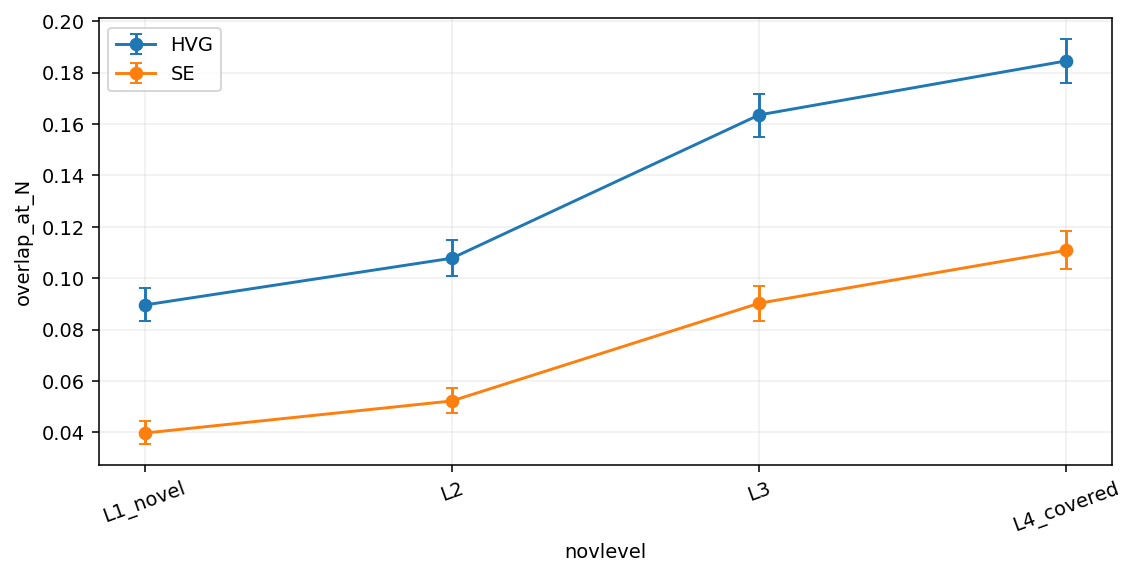

In [11]:
features=pd.read_csv(WORK/'spectra_run/artifacts/replogle_go_features.csv')
features['novlevel']=pd.qcut(features.go_meantop5,4,labels=['L1_novel','L2','L3','L4_covered'])
data=raw[raw.dataset_family.eq('Replogle-Nadig')&raw.protocol.eq('zeroshot')].merge(features,on='perturbation_name',validate='many_to_one')
curve=draw(data,'novlevel','overlap_at_N','representation')

## 6. What the agent decided, and why

Annotation count and perturbation strength explain part of the neighborhood relationship. Fixed-N metrics, partial rank correlations, gene holdout, context/module robustness and effect-matched curves determine how much signal remains.

In [12]:
if 'curve' in globals():
    display(curve)
    for group,q in curve.groupby(curve.columns[0],observed=True):
        if 'mean' in q:print('Ordered mean-score steps:',group,np.diff(q['mean'].to_numpy()))
print('Read the calculated controls above together with the axis curve; a raw association alone does not establish model-specific generalization.')

,representation,novlevel,n,mean,lo,hi
0,HVG,L1_novel,1305,0.089572,0.083151,0.096273
1,HVG,L2,1371,0.107774,0.100871,0.114818
2,HVG,L3,1398,0.163516,0.155036,0.171510
3,HVG,L4_covered,1366,0.184552,0.175863,0.193183
4,SE,L1_novel,1305,0.039735,0.035328,0.044333
5,SE,L2,1371,0.052237,0.047393,0.057333
6,SE,L3,1398,0.090249,0.083460,0.097081
7,SE,L4_covered,1366,0.110838,0.103493,0.118408


Ordered mean-score steps: HVG [0.01820255 0.05574219 0.02103539]
Ordered mean-score steps: SE [0.01250145 0.03801179 0.0205888 ]
Read the calculated controls above together with the axis curve; a raw association alone does not establish model-specific generalization.


In [13]:
(WORK/'execution_record.json').write_text(json.dumps({'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'official_sources':SOURCES,'input_rows':len(raw),'model_inference_performed':False,'external_custom_code_used':False},indent=2))

32015